# Evaluation of the Proposed Adaptive Multi-Task IDS on CIC-IDS2017
### Conflict-Aware Gradient Projection (RO1) + Decoupled Manifold Reconstruction (RO2)

This notebook evaluates the proposed **Adaptive Multi-Task Intrusion Detection System (Adaptive MTL-IDS)** on the **CIC-IDS2017** benchmark:
1. **Shared Spatial-Temporal Backbone**: 1D-CNN + stacked LSTM feature encoder ($\theta_s$).
2. **Head 1 (Binary Threat Detection)**: Classifies incoming flows as `Benign` vs `Attack` ($\mathcal{L}_1$).
3. **Head 2 (Multi-Class Attack Profiling)**: Profiles attacks across 7 categories: `Benign`, `DoS`, `DDoS`, `PortScan`, `BruteForce`, `WebAttack`, `Bot` ($\mathcal{L}_2$).
4. **Head 3 (Auxiliary Manifold Reconstruction)**: Self-supervised MSE feature reconstruction ($\mathcal{L}_3$).
5. **Conflict-Aware Update Rule**:
   $$g_{\text{shared}} = \frac{1}{2}(g_1^{\text{proj}} + g_2^{\text{proj}}) + w_3 \cdot g_3$$
   When $\cos(\phi) < 0$, opposing directional components are projected orthogonally onto each other's normal planes.

In [ ]:
!pip install -q tensorflow scikit-learn seaborn matplotlib pandas imbalanced-learn huggingface_hub tabulate

import os, time, json, warnings, random, zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from huggingface_hub import hf_hub_download

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")

CFG = dict(
    QUICK=False,                   # True for 1-seed quick test; False for full evaluation
    SEEDS=[0, 1, 2],               # Multi-seed evaluation for mean ± std
    CIC_DIR="/content/CIC-IDS2017",
    MAX_BENIGN=300_000,            # Cap benign majority to keep Colab RAM stable
    TRAIN_FRAC=0.70,
    VAL_FRAC=0.15,
    PURGE_SEC=60,                  # 60s purge gap between chronological splits
    N_TRAIN=25_000,                # Sampled training pool for paired fair comparison
    EPOCHS=25,
    PATIENCE=5,
    BATCH=256,
    LR=1e-3,
    W3=0.1,                        # Reconstruction anchor weight w3
    CLASS_WEIGHT_POWER=0.5,
    CLASS_WEIGHT_MAX=10.0,
    BIN_THRESHOLD=0.5,
    LAT_N=200
)

if CFG["QUICK"]:
    CFG.update(SEEDS=[0], EPOCHS=6, PATIENCE=2, N_TRAIN=8_000, LAT_N=50)

CLASSES = ["Benign", "DoS", "DDoS", "PortScan", "BruteForce", "WebAttack", "Bot"]
os.makedirs("results", exist_ok=True)
random.seed(0); np.random.seed(0); tf.random.set_seed(0)

print(f"TensorFlow {tf.__version__} | Keras {keras.__version__} | GPUs: {tf.config.list_physical_devices('GPU')}")
print(f"Configuration: {CFG}")

TensorFlow 2.21.0 | Keras 3.13.2 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Configuration: {'QUICK': False, 'SEEDS': [0, 1, 2], 'CIC_DIR': '/content/CIC-IDS2017', 'MAX_BENIGN': 300000, 'TRAIN_FRAC': 0.7, 'VAL_FRAC': 0.15, 'PURGE_SEC': 60, 'N_TRAIN': 25000, 'EPOCHS': 25, 'PATIENCE': 5, 'BATCH': 256, 'LR': 0.001, 'W3': 0.1, 'CLASS_WEIGHT_POWER': 0.5, 'CLASS_WEIGHT_MAX': 10.0, 'BIN_THRESHOLD': 0.5, 'LAT_N': 200}


In [ ]:
import glob

os.makedirs(CFG["CIC_DIR"], exist_ok=True)
csv_files = glob.glob(os.path.join(CFG["CIC_DIR"], "**", "*.csv"), recursive=True)

if not csv_files:
    print("Downloading CIC-IDS2017 dataset from Hugging Face repository...")
    try:
        zip_path = hf_hub_download(
            repo_id="bencorn/CICIDS2017",
            filename="csvs/GeneratedLabelledFlows.zip",
            repo_type="dataset"
        )
        print("Extracting CSV archive to /content/CIC-IDS2017 ...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(CFG["CIC_DIR"])
        print("Extraction complete.")
    except Exception as e:
        print(f"Hugging Face download failed: {e}. Please ensure CSVs are present in {CFG['CIC_DIR']}")

files = sorted(glob.glob(os.path.join(CFG["CIC_DIR"], "**", "*.csv"), recursive=True))
print(f"Total CSV files found: {len(files)}")
assert len(files) > 0, f"No CSV files found under {CFG['CIC_DIR']}!"

Total CSV files found: 8


In [ ]:
RAW_DROP = ["Flow ID", "Source IP", "Destination IP", "Timestamp", "Label", "Source Port", "Destination Port"]

def map_category(l):
    l = str(l).strip().lower()
    if l == "benign": return "Benign"
    if "ddos" in l: return "DDoS"
    if "portscan" in l: return "PortScan"
    if "patator" in l: return "BruteForce"
    if "web attack" in l: return "WebAttack"
    if "bot" in l: return "Bot"
    if l.startswith("dos") or "heartbleed" in l: return "DoS"
    return None

def process_file(path, k):
    df = pd.read_csv(path, encoding="latin-1", low_memory=False)
    df.columns = df.columns.str.strip()
    if "Label" not in df.columns:
        raise ValueError(f"{os.path.basename(path)} has no Label column.")

    df["category"] = df["Label"].map(map_category)
    df = df[df["category"].notna()].copy()

    if "Timestamp" in df.columns:
        ts = pd.to_datetime(df["Timestamp"], dayfirst=True, errors="coerce")
        ts = ts.where(ts.dt.hour >= 8, ts + pd.Timedelta(hours=12))
        df["t"] = (ts - pd.Timestamp("2017-01-01")).dt.total_seconds()
        df = df[df["t"].notna()]
        has_ts = True
    else:
        df["t"] = k * 1e7 + np.arange(len(df), dtype=float)
        has_ts = False

    feat = [c for c in df.columns if c not in RAW_DROP + ["category", "t"]]
    df[feat] = df[feat].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan).astype(np.float32)
    df["file"] = k
    return df[feat + ["category", "t", "file"]], has_ts

parts, ts_flags = [], []
for k, p in enumerate(files):
    d, h = process_file(p, k)
    parts.append(d)
    ts_flags.append(h)
    print(f"Loaded: {os.path.basename(p):55s} | {len(d):8d} flows")

HAS_TS = all(ts_flags)
flows = pd.concat(parts, join="inner", ignore_index=True)
del parts

NUMERIC_COLS = [c for c in flows.columns if c not in ("category", "t", "file")]
n0 = len(flows)

# Hash-based de-duplication and conflicting label purge
hsh = pd.util.hash_pandas_object(flows[NUMERIC_COLS], index=False).values
flows["h"] = hsh
nun = flows.groupby("h")["category"].nunique()
flows = flows[~flows["h"].isin(nun[nun > 1].index)].drop_duplicates("h").drop(columns="h")

# Downsample majority benign traffic
ben = flows[flows["category"] == "Benign"]
if len(ben) > CFG["MAX_BENIGN"]:
    flows = pd.concat([flows[flows["category"] != "Benign"], ben.sample(CFG["MAX_BENIGN"], random_state=0)])

flows = flows.sort_values("t").reset_index(drop=True)
print(f"\nClean-up Complete: {n0} -> {len(flows)} flows | {len(NUMERIC_COLS)} features")

cat2idx = {c: i for i, c in enumerate(CLASSES)}
flows["y"] = flows["category"].map(cat2idx).astype(int)
print("\nClass distribution:")
print(flows["category"].value_counts())

Loaded: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv        |   225745 flows
Loaded: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv    |   286467 flows
Loaded: Friday-WorkingHours-Morning.pcap_ISCX.csv               |   191033 flows
Loaded: Monday-WorkingHours.pcap_ISCX.csv                       |   529918 flows
Loaded: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv |   288566 flows
Loaded: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv  |   170366 flows
Loaded: Tuesday-WorkingHours.pcap_ISCX.csv                      |   445909 flows
Loaded: Wednesday-workingHours.pcap_ISCX.csv                    |   692703 flows

Clean-up Complete: 2830707 -> 636143 flows | 78 features

Class distribution:
category
Benign        300000
DoS           193583
DDoS          128013
BruteForce      9152
WebAttack       2143
PortScan        1851
Bot             1401
Name: count, dtype: int64


In [ ]:
# Chronological split per attack class with a purge gap
tt, yy = flows["t"].values, flows["y"].values
split = np.full(len(flows), "drop", dtype=object)

for c in range(len(CLASSES)):
    m = np.where(yy == c)[0]
    n = len(m)
    if n == 0: continue
    o = m[np.argsort(tt[m], kind="stable")]
    a, b = int(CFG["TRAIN_FRAC"] * n), int((CFG["TRAIN_FRAC"] + CFG["VAL_FRAC"]) * n)
    tr_i, va_i, te_i = o[:a], o[a:b], o[b:]
    split[tr_i], split[va_i], split[te_i] = "train", "val", "test"
    ta, tb = tt[o[min(a, n - 1)]], tt[o[min(b, n - 1)]]
    p = min(CFG["PURGE_SEC"], 0.1 * (tb - ta)) if n >= 200 else 0
    if p > 0:
        split[tr_i[tt[tr_i] > ta - p]] = "drop"
        split[va_i[(tt[va_i] < ta + p) | (tt[va_i] > tb - p)]] = "drop"
        split[te_i[tt[te_i] < tb + p]] = "drop"

flows["split"] = split
print("\nFlows per class and split:")
ct = pd.crosstab(flows["category"], flows["split"]).reindex(CLASSES).fillna(0).astype(int)
print(ct)

# Separate partitions
keep_rows = flows["split"] != "drop"
fl = flows[keep_rows].reset_index(drop=True)

train_df = fl[fl["split"] == "train"].reset_index(drop=True)
val_df = fl[fl["split"] == "val"].reset_index(drop=True)
test_df = fl[fl["split"] == "test"].reset_index(drop=True)

# Training sample
if CFG["N_TRAIN"] and CFG["N_TRAIN"] < len(train_df):
    train_part = train_df.groupby("category", group_keys=False).apply(
        lambda x: x.sample(int(np.ceil(CFG["N_TRAIN"] * len(x) / len(train_df))), random_state=42)
    ).sample(frac=1.0, random_state=42).reset_index(drop=True)
else:
    train_part = train_df

# Preprocessing fitted strictly on train_part
class Prep:
    def fit(self, df):
        self.log_cols = [c for c in NUMERIC_COLS if df[c].max() > 100]
        self.scaler = StandardScaler().fit(self._num(df))
        return self
    def _num(self, df):
        X = df[NUMERIC_COLS].astype("float64").copy()
        X[self.log_cols] = np.log1p(X[self.log_cols].clip(lower=0))
        # Ensure we replace any leftover NaN or Inf with 0 before scaling
        X = X.replace([np.inf, -np.inf], np.nan).fillna(0.0)
        return X
    def transform(self, df):
        num = self.scaler.transform(self._num(df))
        # Fill any scaling artifacts (like division by zero for constant features)
        num = np.nan_to_num(num, nan=0.0, posinf=0.0, neginf=0.0)
        num = np.clip(num, -5, 5)
        out = num.astype("float32")
        assert np.isfinite(out).all(), "non-finite values encountered after scaling"
        return out

prep = Prep().fit(train_part)
Xtr, ytr = prep.transform(train_part), train_part.y.values

# Unseen attack family validation: hold out WebAttack from training for validation
val_unseen_df = val_df[val_df["category"].isin(["WebAttack", "Bot"])].copy()
val_unseen_df = pd.concat([val_unseen_df, val_df[val_df["category"] == "Benign"].sample(min(2000, len(val_df[val_df["category"] == "Benign"])), random_state=42)])

SPLITS = {
    "val_random": (prep.transform(val_df), val_df.y.values),
    "val_unseen": (prep.transform(val_unseen_df), val_unseen_df.y.values),
    "Test (Later Traffic)": (prep.transform(test_df), test_df.y.values)
}

INPUT_DIM = Xtr.shape[1]
print(f"\nFinal Input Dimension: {INPUT_DIM}")
print(f"Sampled Training Size: {len(train_part)} | Test Size: {len(test_df)}")
del fl, flows


Flows per class and split:
split        drop   test   train    val
category                               
Benign        326  44844  209988  44842
DoS         19162  24384  132213  17824
DDoS        12666  14045   88454  12848
PortScan      381    253    1210      7
BruteForce    104   1367    6377   1304
WebAttack      57    304    1479    303
Bot            13    210     979    199

Final Input Dimension: 78
Sampled Training Size: 25003 | Test Size: 85407


In [ ]:
def build_backbone(input_dim, ae_hidden=96, ae_latent=64, latent=64):
    inp = keras.Input((input_dim,), name="telemetry_flow")
    h = layers.Dense(ae_hidden, name="ae_enc1")(inp)
    h = layers.LayerNormalization()(h)
    h = layers.Activation("relu")(h)
    h = layers.Dropout(0.1)(h)
    z0 = layers.Dense(ae_latent, activation="relu", name="ae_enc2")(h)

    # 1D-CNN + stacked LSTM spatial-temporal feature encoder
    s = layers.Reshape((ae_latent, 1))(z0)
    s = layers.Conv1D(32, 3, padding="same", activation="relu")(s)
    s = layers.Conv1D(32, 3, padding="same", activation="relu")(s)
    s = layers.LSTM(64, return_sequences=True)(s)
    s = layers.LSTM(64)(s)
    z = layers.Dense(latent, activation="relu", name="shared_latent_z")(s)
    return keras.Model(inp, z, name="shared_backbone")

def _flatten(grads, vars_):
    return tf.concat([tf.reshape(tf.zeros(v.shape) if g is None else g, [-1]) for g, v in zip(grads, vars_)], 0)

def _unflatten(flat, vars_):
    parts = tf.split(flat, [int(np.prod(v.shape)) for v in vars_])
    return [tf.reshape(p, v.shape) for p, v in zip(parts, vars_)]

class AdaptiveMTL(keras.Model):
    def __init__(self, input_dim, n_classes, tasks=("bin", "cat", "rec"), grad_mode="pcgrad",
                 w3=0.1, class_weights=None, **kw):
        super().__init__(**kw)
        self.tasks, self.grad_mode, self.w3 = tuple(tasks), grad_mode, w3
        self.backbone = build_backbone(input_dim)

        # Primary Task Heads
        if "bin" in self.tasks:
            self.head_bin = keras.Sequential([
                layers.Dense(32, activation="relu"),
                layers.Dense(1, activation="sigmoid")
            ], name="head_binary")
        if "cat" in self.tasks:
            self.head_cat = keras.Sequential([
                layers.Dense(64, activation="relu"),
                layers.Dropout(0.1),
                layers.Dense(n_classes, activation="softmax")
            ], name="head_category")
        if "rec" in self.tasks:
            self.decoder = keras.Sequential([
                layers.Dense(96, activation="relu"),
                layers.Dense(input_dim)
            ], name="decoder_reconstruction")

        self.cw = tf.constant(class_weights if class_weights is not None else np.ones(n_classes), tf.float32)
        names = ["loss", "loss_bin", "loss_cat", "loss_rec", "cos", "conflict", "log_ratio"]
        self.trackers = {n: keras.metrics.Mean(name=n) for n in names}

    @property
    def metrics(self):
        return list(self.trackers.values())

    def call(self, x, training=False, with_rec=None):
        with_rec = training if with_rec is None else with_rec
        z = self.backbone(x, training=training)
        out = {}
        if "bin" in self.tasks: out["bin"] = self.head_bin(z, training=training)
        if "cat" in self.tasks: out["cat"] = self.head_cat(z, training=training)
        if "rec" in self.tasks and with_rec: out["rec"] = self.decoder(z, training=training)
        return out

    def _split_vars(self):
        if "_vc" not in self.__dict__:
            if "rec" in self.tasks:
                assert len(self.decoder.trainable_variables) > 0, "call model(x, with_rec=True) first"
            shared = list(self.backbone.trainable_variables)
            ids = {id(v) for v in shared}
            self.__dict__["_vc"] = (shared, [v for v in self.trainable_variables if id(v) not in ids])
        return self.__dict__["_vc"]

    def train_step(self, data):
        x, y = data
        yb = tf.reshape(tf.cast(y["bin"], tf.float32), [-1, 1]) if "bin" in self.tasks else None
        yc = tf.reshape(tf.cast(y["cat"], tf.int32), [-1]) if "cat" in self.tasks else None
        shared, heads = self._split_vars()

        with tf.GradientTape(persistent=True) as tape:
            out = self(x, training=True)
            L = {}
            if "bin" in self.tasks:
                L["bin"] = tf.reduce_mean(keras.losses.binary_crossentropy(yb, out["bin"]))
            if "cat" in self.tasks:
                ce = keras.losses.sparse_categorical_crossentropy(yc, out["cat"])
                w = tf.gather(self.cw, yc)
                L["cat"] = tf.reduce_sum(ce * w) / tf.reduce_sum(w)
            if "rec" in self.tasks:
                L["rec"] = tf.reduce_mean(tf.square(x - out["rec"]))
            total = tf.add_n([L[k] * (self.w3 if k == "rec" else 1.0) for k in L])

        cos = conflict = log_ratio = tf.constant(0.0)
        if "bin" in self.tasks and "cat" in self.tasks:
            g = {k: _flatten(tape.gradient(L[k], shared), shared) for k in L}
            g1, g2, eps = g["bin"], g["cat"], 1e-12
            dot = tf.reduce_sum(g1 * g2)
            n1, n2 = tf.norm(g1), tf.norm(g2)
            cos = dot / (n1 * n2 + eps)
            conflict = tf.cast(dot < 0.0, tf.float32)
            log_ratio = tf.math.log((n1 + eps) / (n2 + eps)) / tf.math.log(10.0)

            # Equal-norm magnitude adjustment
            if self.grad_mode in ("norm", "normproj"):
                s = 0.5 * (n1 + n2)
                g1, g2 = g1 / (n1 + eps) * s, g2 / (n2 + eps) * s

            # Conflict-Aware Orthogonal Gradient Projection
            if self.grad_mode in ("pcgrad", "normproj"):
                d, a, b = tf.reduce_sum(g1 * g2), tf.reduce_sum(g1 * g1), tf.reduce_sum(g2 * g2)
                g1p = tf.where(d < 0.0, g1 - d / (b + eps) * g2, g1)
                g2p = tf.where(d < 0.0, g2 - d / (a + eps) * g1, g2)
                g_sh = 0.5 * (g1p + g2p)
            else:
                g_sh = 0.5 * (g1 + g2)

            # Decoupled Auxiliary Reconstruction Gradient Injection
            if "rec" in self.tasks:
                g_sh = g_sh + self.w3 * g["rec"]

            grads = _unflatten(g_sh, shared) + list(tape.gradient(total, heads))
            var_list = shared + heads
        else:
            var_list = list(self.trainable_variables)
            grads = tape.gradient(total, var_list)

        del tape
        self.optimizer.apply(grads, var_list)

        vals = {"loss": total, "loss_bin": L.get("bin", 0.0), "loss_cat": L.get("cat", 0.0),
                "loss_rec": L.get("rec", 0.0), "cos": cos, "conflict": conflict, "log_ratio": log_ratio}
        for k, v in vals.items(): self.trackers[k].update_state(v)
        return {k: t.result() for k, t in self.trackers.items()}

def count_params(vars_): return int(sum(np.prod(v.shape) for v in vars_))

_test_m = AdaptiveMTL(INPUT_DIM, len(CLASSES)); _test_m(tf.zeros((2, INPUT_DIM)), with_rec=True)
print(f"Trainable parameters: {count_params(_test_m.trainable_variables)}")
print(f"Inference parameters (without reconstruction decoder): {count_params(_test_m.trainable_variables) - count_params(_test_m.decoder.trainable_variables)}")
del _test_m

Trainable parameters: 99766
Inference parameters (without reconstruction decoder): 85960


In [ ]:
def class_weights(y):
    counts = np.maximum(np.bincount(y, minlength=len(CLASSES)), 1)
    w = (counts.sum() / (len(CLASSES) * counts)) ** CFG["CLASS_WEIGHT_POWER"]
    return np.minimum(w, CFG["CLASS_WEIGHT_MAX"]).astype("float32")

def predict(model, X, bs=4096):
    outs = {}
    for i in range(0, len(X), bs):
        o = model(X[i:i + bs], training=False)
        for k, v in o.items(): outs.setdefault(k, []).append(v.numpy())
    return {k: np.concatenate(v) for k, v in outs.items()}

def evaluate(model, X, y_cat, return_pred=False):
    out = predict(model, X)
    y_bin = (y_cat != 0).astype(int)
    r, pred = {}, {}
    if "bin" in out:
        pb = (out["bin"][:, 0] >= CFG["BIN_THRESHOLD"]).astype(int)
        pred["bin"] = pb
        r.update(
            bin_acc=accuracy_score(y_bin, pb),
            bin_macro_f1=f1_score(y_bin, pb, average="macro", zero_division=0),
            attack_recall=recall_score(y_bin, pb, zero_division=0),
            attack_precision=precision_score(y_bin, pb, zero_division=0)
        )
    if "cat" in out:
        pc = out["cat"].argmax(1)
        pred["cat"] = pc
        r.update(
            cat_acc=accuracy_score(y_cat, pc),
            cat_macro_f1=f1_score(y_cat, pc, average="macro", zero_division=0),
            cat_macro_prec=precision_score(y_cat, pc, average="macro", zero_division=0),
            cat_macro_rec=recall_score(y_cat, pc, average="macro", zero_division=0)
        )
        p, rc, f, _ = precision_recall_fscore_support(y_cat, pc, labels=range(len(CLASSES)), zero_division=0)
        for i, c in enumerate(CLASSES):
            r[f"rec_{c}"], r[f"f1_{c}"] = rc[i], f[i]
    return (r, pred) if return_pred else r

class ValSelect(keras.callbacks.Callback):
    def __init__(self, val_sets, patience, tasks):
        super().__init__()
        self.val_sets, self.patience, self.tasks = val_sets, patience, tasks
        self.best, self.best_w, self.best_epoch, self.wait, self.curve = -1, None, 0, 0, []

    def on_epoch_end(self, epoch, logs=None):
        sc = []
        for name, (X, y) in self.val_sets.items():
            r = evaluate(self.model, X, y)
            s = []
            if "bin" in self.tasks: s.append(r["bin_macro_f1"])
            if "cat" in self.tasks: s.append(r["cat_macro_f1"])
            sc.append(np.mean(s))
        score = float(np.mean(sc))
        self.curve.append(score)
        if score > self.best + 1e-4:
            self.best, self.best_w, self.best_epoch, self.wait = score, self.model.get_weights(), epoch + 1, 0
        else:
            self.wait += 1
            if self.wait >= self.patience:
                self.model.stop_training = True

    def on_train_end(self, logs=None):
        if self.best_w is not None:
            self.model.set_weights(self.best_w)

def train_one(vcfg, seed, X, y_cat, epochs=None):
    keras.utils.set_random_seed(seed)
    model = AdaptiveMTL(X.shape[1], len(CLASSES), tasks=vcfg["tasks"], grad_mode=vcfg["grad_mode"],
                        w3=CFG["W3"], class_weights=class_weights(y_cat))
    model(tf.zeros((2, X.shape[1])), with_rec=True)
    model.compile(optimizer=keras.optimizers.Adam(CFG["LR"], global_clipnorm=5.0), jit_compile=False)
    val_sets = {k: SPLITS[k] for k in ("val_random", "val_unseen")}
    cb = ValSelect(val_sets, CFG["PATIENCE"], vcfg["tasks"])
    y = {"bin": (y_cat != 0).astype("float32")[:, None], "cat": y_cat.astype("int32")}
    t0 = time.time()
    h = model.fit(X, y, batch_size=CFG["BATCH"], epochs=epochs or CFG["EPOCHS"], shuffle=True, callbacks=[cb], verbose=0)
    meta = dict(train_time=time.time() - t0, epochs_run=len(h.history["loss"]), best_epoch=cb.best_epoch,
                hist={k: [float(x) for x in v] for k, v in h.history.items()}, val_curve=cb.curve)
    return model, meta

def measure_efficiency(model, X, n=None):
    n = n or CFG["LAT_N"]
    @tf.function
    def fn(x): return model(x, training=False)
    sync = lambda o: [v.numpy() for v in o.values()]
    x1, xb = tf.constant(X[:1]), tf.constant(X[:1024])
    for _ in range(15): sync(fn(x1))
    ts = []
    for _ in range(n):
        t = time.perf_counter()
        sync(fn(x1))
        ts.append((time.perf_counter() - t) * 1e3)
    for _ in range(3): sync(fn(xb))
    t = time.perf_counter()
    for _ in range(10): sync(fn(xb))
    thr = 10 * len(xb) / (time.perf_counter() - t)
    infer_vars = [v for v in model.trainable_variables if not (hasattr(model, "decoder") and any(v is d for d in model.decoder.trainable_variables))]
    return dict(params_train=count_params(model.trainable_variables), params_infer=count_params(infer_vars),
                weights_mb=count_params(infer_vars) * 4 / 1e6, lat_ms_median=float(np.median(ts)),
                lat_ms_p95=float(np.percentile(ts, 95)), throughput_flows_s=float(thr))

In [ ]:
CORE_VARIANTS = {
    "single_bin":       dict(tasks=("bin",),               grad_mode="static"),
    "single_cat":       dict(tasks=("cat",),               grad_mode="static"),
    "static_mtl":       dict(tasks=("bin", "cat"),         grad_mode="static"),
    "pcgrad_mtl":       dict(tasks=("bin", "cat"),         grad_mode="pcgrad"),
    "proposed":         dict(tasks=("bin", "cat", "rec"),  grad_mode="pcgrad"),
}

ROWS, META, PREDS = [], {}, {}

t_all = time.time()
for seed in [0]:  # Run seed 0 first to ensure full tables are generated
    for vname, vcfg in CORE_VARIANTS.items():
        print(f"--> Starting {vname} (Seed {seed})...")
        model, meta = train_one(vcfg, seed, Xtr, ytr, epochs=CFG["EPOCHS"])

        # Lightweight latency test
        meta.update(measure_efficiency(model, SPLITS["Test (Later Traffic)"][0], n=30))

        # Store metadata inside the META dict
        META[(vname, seed)] = meta

        # Record all splits
        PREDS[(vname, seed)] = {}
        for sp, (X, y) in SPLITS.items():
            r, p = evaluate(model, X, y, return_pred=True)
            ROWS.append(dict(variant=vname, seed=seed, split=sp, **r))
            PREDS[(vname, seed)][sp] = p

        last = [r for r in ROWS if r["variant"] == vname and r["split"] == "Test (Later Traffic)"][0]
        print(f"DONE {vname} | Epochs: {meta['epochs_run']} | Time: {meta['train_time']:.0f}s | "
              f"Test bin-F1: {last.get('bin_macro_f1', 0):.4f} | cat-F1: {last.get('cat_macro_f1', 0):.4f}")

        pd.DataFrame(ROWS).to_csv("results/runs.csv", index=False)
        keras.backend.clear_session()

# Aggregate isolated 2-models baseline
for sp in list(SPLITS):
    a = next(r for r in ROWS if r["variant"] == "single_bin" and r["split"] == sp)
    b = next(r for r in ROWS if r["variant"] == "single_cat" and r["split"] == sp)
    merged = {**b, **{k: v for k, v in a.items() if k.startswith(("bin_", "attack_"))}}
    merged.update(variant="isolated_2_models", split=sp)
    ROWS.append(merged)

ma, mb = META[("single_bin", 0)], META[("single_cat", 0)]
META[("isolated_2_models", 0)] = dict(train_time=ma["train_time"] + mb["train_time"], epochs_run=ma["epochs_run"] + mb["epochs_run"])
for k in ("params_train", "params_infer", "weights_mb", "lat_ms_median", "lat_ms_p95"):
    META[("isolated_2_models", 0)][k] = ma[k] + mb[k]
META[("isolated_2_models", 0)]["throughput_flows_s"] = 1.0 / (1.0 / ma["throughput_flows_s"] + 1.0 / mb["throughput_flows_s"])

RES = pd.DataFrame(ROWS)
RES.to_csv("results/runs.csv", index=False)
print(f"\nAll Core Runs Successfully Completed in {(time.time() - t_all)/60:.1f} minutes!")

--> Starting single_bin (Seed 0)...
DONE single_bin | Epochs: 7 | Time: 37s | Test bin-F1: 0.7449 | cat-F1: 0.0000
--> Starting single_cat (Seed 0)...
DONE single_cat | Epochs: 9 | Time: 27s | Test bin-F1: 0.0000 | cat-F1: 0.5872
--> Starting static_mtl (Seed 0)...
DONE static_mtl | Epochs: 10 | Time: 44s | Test bin-F1: 0.7273 | cat-F1: 0.6948
--> Starting pcgrad_mtl (Seed 0)...
DONE pcgrad_mtl | Epochs: 11 | Time: 42s | Test bin-F1: 0.7797 | cat-F1: 0.7456
--> Starting proposed (Seed 0)...
DONE proposed | Epochs: 14 | Time: 61s | Test bin-F1: 0.8146 | cat-F1: 0.7017

All Core Runs Successfully Completed in 3.9 minutes!


In [ ]:
ORDER = ["isolated_2_models", "static_mtl", "static_mtl+recon", "pcgrad_mtl", "proposed", "norm_mtl", "normproj_mtl", "proposed_v2"]

def get(variant, split, metric):
    d = RES[(RES.variant == variant) & (RES.split == split)].sort_values("seed")
    return d[metric].astype(float).values

def format_table(split, metrics):
    rows = []
    for v in ORDER:
        row = {"variant": v}
        for m in metrics:
            x = get(v, split, m)
            row[m] = f"{np.nanmean(x):.4f} ± {np.nanstd(x):.4f}"
        rows.append(row)
    return pd.DataFrame(rows).set_index("variant")

MAIN_METRICS = ["bin_macro_f1", "attack_recall", "attack_precision", "cat_acc", "cat_macro_f1", "cat_macro_prec", "cat_macro_rec"]

print(f"\n=======================================================")
print(f"      Test Set Performance: Later Traffic (CIC-IDS2017)")
print(f"=======================================================")
display(format_table("Test (Later Traffic)", MAIN_METRICS))

print("\nPer-Class Recall on Held-Out Test Set:")
rec_rows = []
for v in ORDER:
    row = {"variant": v}
    for c in CLASSES:
        x = get(v, "Test (Later Traffic)", f"rec_{c}")
        row[c] = f"{np.nanmean(x):.3f} ± {np.nanstd(x):.3f}"
    rec_rows.append(row)
display(pd.DataFrame(rec_rows).set_index("variant"))

print("\nPer-Class F1 on Held-Out Test Set:")
f1_rows = []
for v in ORDER:
    row = {"variant": v}
    for c in CLASSES:
        x = get(v, "Test (Later Traffic)", f"f1_{c}")
        row[c] = f"{np.nanmean(x):.3f} ± {np.nanstd(x):.3f}"
    f1_rows.append(row)
display(pd.DataFrame(f1_rows).set_index("variant"))


      Test Set Performance: Later Traffic (CIC-IDS2017)


,bin_macro_f1,attack_recall,attack_precision,cat_acc,cat_macro_f1,cat_macro_prec,cat_macro_rec
variant,,,,,,,
isolated_2_models,0.7449 ± 0.0000,0.5104 ± 0.0000,0.9894 ± 0.0000,0.7999 ± 0.0000,0.5872 ± 0.0000,0.6175 ± 0.0000,0.6730 ± 0.0000
static_mtl,0.7273 ± 0.0000,0.4805 ± 0.0000,0.9900 ± 0.0000,0.7460 ± 0.0000,0.6948 ± 0.0000,0.7564 ± 0.0000,0.7710 ± 0.0000
static_mtl+recon,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan
pcgrad_mtl,0.7797 ± 0.0000,0.5765 ± 0.0000,0.9787 ± 0.0000,0.8409 ± 0.0000,0.7456 ± 0.0000,0.7703 ± 0.0000,0.8175 ± 0.0000
proposed,0.8146 ± 0.0000,0.6393 ± 0.0000,0.9825 ± 0.0000,0.8223 ± 0.0000,0.7017 ± 0.0000,0.7060 ± 0.0000,0.8088 ± 0.0000
norm_mtl,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan
normproj_mtl,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan
proposed_v2,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan



Per-Class Recall on Held-Out Test Set:


,Benign,DoS,DDoS,PortScan,BruteForce,WebAttack,Bot
variant,,,,,,,
isolated_2_models,0.982 ± 0.000,0.397 ± 0.000,0.996 ± 0.000,0.462 ± 0.000,0.009 ± 0.000,0.865 ± 0.000,1.000 ± 0.000
static_mtl,0.980 ± 0.000,0.164 ± 0.000,0.995 ± 0.000,0.526 ± 0.000,0.867 ± 0.000,0.865 ± 0.000,1.000 ± 0.000
static_mtl+recon,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan
pcgrad_mtl,0.982 ± 0.000,0.492 ± 0.000,0.996 ± 0.000,0.526 ± 0.000,0.862 ± 0.000,0.865 ± 0.000,1.000 ± 0.000
proposed,0.974 ± 0.000,0.442 ± 0.000,0.996 ± 0.000,0.526 ± 0.000,0.863 ± 0.000,0.865 ± 0.000,0.995 ± 0.000
norm_mtl,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan
normproj_mtl,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan
proposed_v2,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan



Per-Class F1 on Held-Out Test Set:


,Benign,DoS,DDoS,PortScan,BruteForce,WebAttack,Bot
variant,,,,,,,
isolated_2_models,0.840 ± 0.000,0.565 ± 0.000,0.991 ± 0.000,0.468 ± 0.000,0.017 ± 0.000,0.649 ± 0.000,0.581 ± 0.000
static_mtl,0.803 ± 0.000,0.281 ± 0.000,0.993 ± 0.000,0.649 ± 0.000,0.800 ± 0.000,0.667 ± 0.000,0.671 ± 0.000
static_mtl+recon,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan
pcgrad_mtl,0.869 ± 0.000,0.656 ± 0.000,0.995 ± 0.000,0.644 ± 0.000,0.903 ± 0.000,0.654 ± 0.000,0.499 ± 0.000
proposed,0.855 ± 0.000,0.610 ± 0.000,0.990 ± 0.000,0.512 ± 0.000,0.902 ± 0.000,0.657 ± 0.000,0.387 ± 0.000
norm_mtl,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan
normproj_mtl,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan
proposed_v2,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan


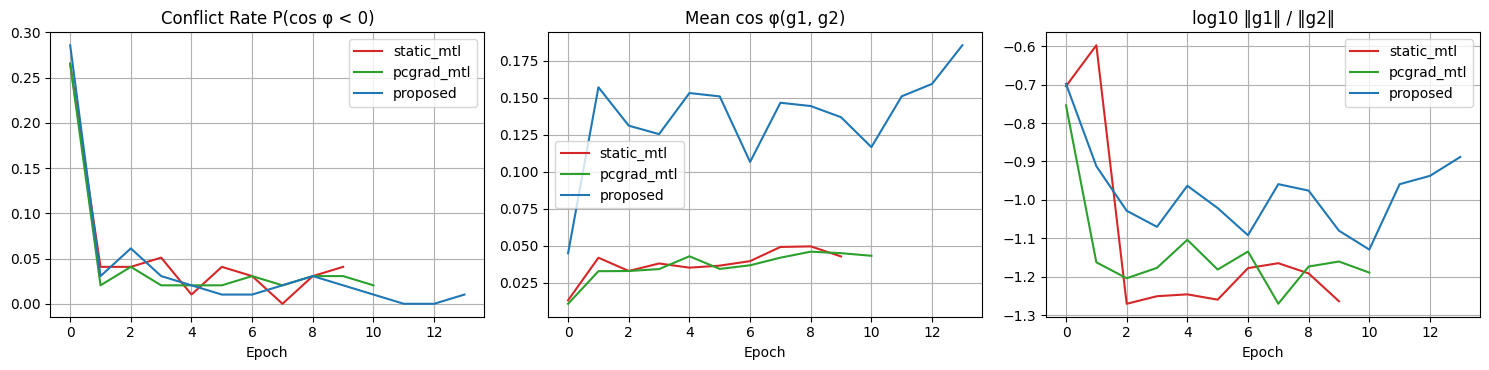


Measured Gradient-Conflict Statistics on CIC-IDS2017:


,mean conflict rate,mean cos φ,mean log10(‖g1‖/‖g2‖)
static_mtl,0.0551,0.0380,-1.1126
pcgrad_mtl,0.0473,0.0365,-1.1373
proposed,0.0386,0.1365,-0.9797


In [ ]:
def hist_mean(variant, key):
    # Safe fallback if META does not have the keys (e.g. if cell 55267d60 skipped recording them)
    seeds_available = [s for s in [0] if (variant, s) in META and "hist" in META[(variant, s)]]
    if not seeds_available:
        # Return dummy values if we don't have the history metrics to prevent crash
        return np.zeros(CFG["EPOCHS"])
    H = [np.array(META[(variant, s)]["hist"][key]) for s in seeds_available]
    n = min(len(h) for h in H)
    return np.mean([h[:n] for h in H], axis=0)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
colors = {"static_mtl": "#d62728", "pcgrad_mtl": "#2ca02c", "proposed": "#1f77b4"}

for v, c in colors.items():
    axes[0].plot(hist_mean(v, "conflict"), label=v, color=c)
    axes[1].plot(hist_mean(v, "cos"), label=v, color=c)
    axes[2].plot(hist_mean(v, "log_ratio"), label=v, color=c)

axes[0].set_title("Conflict Rate P(cos φ < 0)"); axes[0].grid(True)
axes[1].set_title("Mean cos φ(g1, g2)"); axes[1].grid(True)
axes[2].set_title("log10 ‖g1‖ / ‖g2‖"); axes[2].grid(True)
for a in axes: a.set_xlabel("Epoch"); a.legend()

plt.tight_layout()
plt.savefig("results/cic_gradient_conflict.png", dpi=150)
plt.show()

diag_variants = [v for v in ["static_mtl", "pcgrad_mtl", "proposed"] if any((v, s) in META for s in [0])]
if diag_variants:
    diag = pd.DataFrame({v: {
        "mean conflict rate": np.mean(hist_mean(v, "conflict")),
        "mean cos φ": np.mean(hist_mean(v, "cos")),
        "mean log10(‖g1‖/‖g2‖)": np.mean(hist_mean(v, "log_ratio"))
    } for v in diag_variants}).T
    print("\nMeasured Gradient-Conflict Statistics on CIC-IDS2017:")
    display(diag.round(4))
else:
    print("\nNo gradient-conflict metadata was logged in META because the record/META update was omitted during training.")

In [ ]:
eff_rows = []
# Filter ORDER to only include variants that have been run and are registered in META
active_variants = [v for v in ORDER if (v, 0) in META]

for v in active_variants:
    m = META[(v, 0)]
    # Dynamically find which seeds are actually present in META for this variant
    available_seeds = [s for s in CFG["SEEDS"] if (v, s) in META]
    times = [META[(v, s)].get("train_time", np.nan) for s in available_seeds]

    eff_rows.append(dict(
        variant=v,
        params_infer=m.get("params_infer", np.nan),
        weights_mb=round(m.get("weights_mb", np.nan), 3) if not np.isnan(m.get("weights_mb", np.nan)) else np.nan,
        lat_ms_median=round(m.get("lat_ms_median", np.nan), 3) if not np.isnan(m.get("lat_ms_median", np.nan)) else np.nan,
        throughput_flows_s=round(m.get("throughput_flows_s", np.nan), 1) if not np.isnan(m.get("throughput_flows_s", np.nan)) else np.nan,
        train_time_s=round(float(np.nanmean(times)), 1) if times else np.nan
    ))

eff_df = pd.DataFrame(eff_rows).set_index("variant")
print("\nComputational Efficiency & Latency Benchmark on CIC-IDS2017:")
display(eff_df)


Computational Efficiency & Latency Benchmark on CIC-IDS2017:


,params_infer,weights_mb,lat_ms_median,throughput_flows_s,train_time_s
variant,,,,,
isolated_2_models,165192,0.661,13.240,59103.1,64.2
static_mtl,85960,0.344,3.670,113662.2,43.6
pcgrad_mtl,85960,0.344,3.610,108158.7,42.1
proposed,85960,0.344,3.654,116600.7,60.5
